> **Save your own copy first.** Unless this notebook is already in your own Google Drive, Colab does not keep your changes. Go to **File → Save a copy in Drive** and work in the copy that opens in a new tab. You find it later in Google Drive, in *Colab Notebooks*.

# CDA Week2: Data Analysis with Pandas: TikTok and the "iran war" query

*Cultural Data Analysis, week 2 — workshop notebook. Hand in through Canvas as a HTML file (see last cell) before Monday, 13:00.*

**Before you start:** make a copy of this notebook in your own Drive (`File` → `Save a copy in Drive`).

This notebook mirrors the lecture notebook (the Eurovision one) step by step: **open → inspect → clean → select, derive & filter → analyze & visualize → write back**. The difference is that here *you* write part of the code, and on a very different kind of data: posts collected from TikTok. Keep the lecture notebook open next to this one; almost every task uses a function that appears there, and the hint in each task tells you which one.

There are three kinds of cells:

1. **Given cells** (sections 0 and 1, and the tasks marked *given*): the code is there, run it and read it. A given cell shows a pattern that the tasks after it use.
2. **Task cells** with a hint (`# hint: ...`): write one or a few lines of code.
3. **Interpretation cells** (marked **Methods question.**): one or two sentences in your own words. These are as important as the code.

Towards the end, a few tasks ask you to predict an output before running a cell, to repair code that is wrong, and to use an AI assistant for one task and verify what it produced.

## The case

The data file contains **353 TikTok posts** collected on 13 October 2026 by searching TikTok for *iran war*, opening the "Videos" tab of the results, and scrolling down until the page stopped loading new posts. The collection was made with [Zeeschuimer](https://github.com/digitalmethodsinitiative/zeeschuimer), a browser extension that records the metadata of every post the TikTok interface loads while you browse: author, caption, sound, hashtags, and engagement counts as they were at that moment. It does not download the videos. The file is Zeeschuimer's direct CSV export.

The questions come from two studies that also work with TikTok metadata collected with this kind of tool (full references at the end): Pilipets and Chao (2026) follow *sounds* across posts and show how an "original sound" of one user turns into a template reused by others; Bösch and Divon (2024) argue that sound is the channel through which war-related content and propaganda travel on TikTok.

* **RQ1 — Who posts "iran war" content in this sample, and whose posts get viewed?** News organizations or individual accounts; do followers translate into plays?
* **RQ2 — Through which sounds does the content travel?** A post's own sound, someone else's reused sound, or music?
* **RQ3 — When were the posts made, and what does the timeline show:** the war, or the search engine?
* **RQ4 — Which hashtags frame the content,** and which hashtags appear together with #iran?

> **Methods question**. Before you run anything: what is this sample? Not "TikTok posts about the Iran war", but TikTok's ranked answer to one query, in one account's interface, on one day, with the counts of that moment. Keep this in mind for every number you produce.

## 0. Setup

Same libraries as in the lecture.

In [10]:
import pandas as pd
if pd.__version__ < "3":                  # pandas 3 behaves like this by default
    pd.options.mode.copy_on_write = True

import matplotlib.pyplot as plt
import seaborn as sns

## 1. Opening the file

Copy `tiktok_iran_war.csv` from the shared folder into your own Google Drive, mount the Drive, and put the path to the file in `file_path` (right-click the file in Colab's file browser and choose "copy path").

In [11]:
# commented out because I have the file locally
# try:
#     from google.colab import drive
#     drive.mount('/content/drive')
# except ImportError:
#     print('Not running in Colab, no Drive to mount.')

In [12]:
# import os

# try:
#     import google.colab
#     file_path = '/content/drive/MyDrive/tiktok_iran_war.csv'      # replace with the path to the file in your Drive
# except ImportError:
#     # On your own computer: put tiktok_iran_war.csv in the same folder as this notebook
#     file_path = 'tiktok_iran_war.csv'

# if os.path.exists(file_path):
#     print('Found', os.path.abspath(file_path))
# else:
#     print('File not found:', os.path.abspath(file_path))
#     print('Download tiktok_iran_war.csv from the shared folder and put it there.')

Now read the file with `pd.read_csv()`, exactly as in the lecture. **This cell is supposed to fail.** Run it and read the error message to the end.

In [13]:
df = pd.read_csv('tiktok_iran_war.csv')

ParserError: Error tokenizing data. C error: Expected 11 fields in line 6, saw 13


The message says what pandas expected and what it found in line 6, not why. The why is in the file itself: open it in a text editor or in [Modern CSV](https://www.moderncsv.com/) and look at the first line. What separates the columns? In a CSV from Zeeschuimer it is not a comma but a semicolon, and `read_csv()` has a parameter for that.

In [15]:
df = pd.read_csv('tiktok_iran_war.csv', sep=';')
df

,collected_from_url,id,thread_id,author,author_full,author_followers,author_likes,author_videos,body,stickers,...,likes,comments,shares,plays,hashtags,challenges,diversification_labels,location_created,effects,warning
0,https://www.tiktok.com/search/video?q=iran%20w...,7695733500179254550,7695733500179254550,olivia.reed86,Olivia Reed Information,49600,38,190,"IRAN DECLARES WAR ON MEDIA! BBC, Iran Internat...",NaN,...,100,4,13,2824,"breakingnews,iran,middleeast,geopolitics,bbc","breakingnews,iran,middleeast,geopolitics,bbc",NaN,NaN,NaN,NaN
1,https://www.tiktok.com/search/video?q=iran%20w...,7694261148136328479,7694261148136328479,prof.jiang2,Prof. Jiang,45900,3696,128,thus war in middle east surprised me#profjiang...,NaN,...,2146,85,176,45100,"profjiang,middleeastwar,iranwar,podcast,creato...","profjiang,middleeastwar,iranwar,podcast,creato...",NaN,NaN,NaN,NaN
2,https://www.tiktok.com/search/video?q=iran%20w...,7695226728075087134,7695226728075087134,ashley.west008,Ashley West,10300,4,143,21.September.2026 Iran 🇮🇷 drops more warnings ...,NaN,...,184,7,8,5786,"newsbaba,geopolitics,analysis,news,latest","newsbaba,geopolitics,analysis,news,latest",NaN,NaN,NaN,NaN
3,https://www.tiktok.com/search/video?q=iran%20w...,7695904002277510414,7695904002277510414,big.news.today0,BIG News ✨,993,458,8,Tje Latest News From US Iran War #cia #agent #...,NaN,...,39,1,0,889,"cia,agent,johnkiriakou,usnews,usiran","cia,agent,johnkiriakou,usnews,usiran",NaN,NaN,NaN,NaN
4,https://www.tiktok.com/search/video?q=iran%20w...,7694024867745729814,7694024867745729814,breakingnews5021,Breaking news,12200,58,46,IRAN ATACA UN PORTAAVIONES DE EE.UU.! MISILES ...,NaN,...,237,3,9,11400,"ultimahora,iran,unitedstates,guerra,news,break...","ultimahora,iran,unitedstates,guerra,news,break...",NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
348,https://www.tiktok.com/search/video?q=iran%20w...,7612572196086582548,7612572196086582548,hope.love.grace8,HOPE LOVE GRACE,424500,111,290,#sad #save #children #fyp #Iran,NaN,...,7800000,254200,374500,175700000,"sad,save,children,fyp,iran","sad,save,children,fyp,iran",NaN,NaN,NaN,NaN
349,https://www.tiktok.com/search/video?q=iran%20w...,7695515256038165793,7695515256038165793,eaglenews29,𝙀𝙖𝙜𝙡𝙚 𝙉𝙚𝙬𝙨🦅,1640,1095,537,A senior Iranian official is warning that Tehr...,NaN,...,15,0,0,952,"iran,straitofhormuz,middleeast,worldnews,geopo...","iran,straitofhormuz,middleeast,worldnews,geopo...",NaN,NaN,NaN,NaN
350,https://www.tiktok.com/search/video?q=iran%20w...,7695142381863144718,7695142381863144718,michiganwatcherap,MichiganWatcherApp,58,78,20,just a lil meme to call for peace with Iran. ...,NaN,...,5,0,0,361,"nowar,nowaroniran,peace,iran,war","nowar,nowaroniran,peace,iran,war",NaN,NaN,NaN,NaN
351,https://www.tiktok.com/search/video?q=iran%20w...,7695798733870599446,7695798733870599446,theviralbreif,The Viral Breif,458,185,913,What happens when the infrastructure behind ev...,NaN,...,13,1,0,2044,NaN,NaN,NaN,NaN,NaN,NaN


The first column, `collected_from_url`, is new compared with last year's files: Zeeschuimer records the page from which each post was captured.

In [16]:
df['collected_from_url'].unique()

<StringArray>
['https://www.tiktok.com/search/video?q=iran%20war&t=1791897472314']
Length: 1, dtype: str

**Methods question.** What does this URL tell you about how the sample was made, and name one thing the sample therefore leaves out.

WRITE HERE
I think that the researchers used the tiktok search function and collected all links from artifacts, that have the names 'iran' and 'war' in them. Sadly the link doesnt work anymore so I cannot open it. I think it wouldve been nice to clone the repository somehow (dont think thats possible with proprietary apps/ platforms / data) so it can be persistent after the artifact is deleted. I think the search is for direct matches that have the metadata (labels). Therefore videos that are about that but not labelled as that are not part of the repo. I can imagine Tiktok is using a kind of automated metadata enhancer that is scraping the content and assigns labels for the recommendation engine.
Also all results come from a single query (?)

## 2. Inspecting

**Task 2.1 (given)** — The first three and the last three rows of `df`. Run the cell and read it: `display()` shows both tables from one cell (on its own, a cell only shows its last value).

In [17]:
display(df.head(3))     # display() shows several tables from one cell; without it, a cell only shows its last value
display(df.tail(3))

,collected_from_url,id,thread_id,author,author_full,author_followers,author_likes,author_videos,body,stickers,...,likes,comments,shares,plays,hashtags,challenges,diversification_labels,location_created,effects,warning
0,https://www.tiktok.com/search/video?q=iran%20w...,7695733500179254550,7695733500179254550,olivia.reed86,Olivia Reed Information,49600,38,190,"IRAN DECLARES WAR ON MEDIA! BBC, Iran Internat...",NaN,...,100,4,13,2824,"breakingnews,iran,middleeast,geopolitics,bbc","breakingnews,iran,middleeast,geopolitics,bbc",NaN,NaN,NaN,NaN
1,https://www.tiktok.com/search/video?q=iran%20w...,7694261148136328479,7694261148136328479,prof.jiang2,Prof. Jiang,45900,3696,128,thus war in middle east surprised me#profjiang...,NaN,...,2146,85,176,45100,"profjiang,middleeastwar,iranwar,podcast,creato...","profjiang,middleeastwar,iranwar,podcast,creato...",NaN,NaN,NaN,NaN
2,https://www.tiktok.com/search/video?q=iran%20w...,7695226728075087134,7695226728075087134,ashley.west008,Ashley West,10300,4,143,21.September.2026 Iran 🇮🇷 drops more warnings ...,NaN,...,184,7,8,5786,"newsbaba,geopolitics,analysis,news,latest","newsbaba,geopolitics,analysis,news,latest",NaN,NaN,NaN,NaN


,collected_from_url,id,thread_id,author,author_full,author_followers,author_likes,author_videos,body,stickers,...,likes,comments,shares,plays,hashtags,challenges,diversification_labels,location_created,effects,warning
350,https://www.tiktok.com/search/video?q=iran%20w...,7695142381863144718,7695142381863144718,michiganwatcherap,MichiganWatcherApp,58,78,20,just a lil meme to call for peace with Iran. ...,NaN,...,5,0,0,361,"nowar,nowaroniran,peace,iran,war","nowar,nowaroniran,peace,iran,war",NaN,NaN,NaN,NaN
351,https://www.tiktok.com/search/video?q=iran%20w...,7695798733870599446,7695798733870599446,theviralbreif,The Viral Breif,458,185,913,What happens when the infrastructure behind ev...,NaN,...,13,1,0,2044,NaN,NaN,NaN,NaN,NaN,NaN
352,https://www.tiktok.com/search/video?q=iran%20w...,7617661250889108749,7617661250889108749,realasaljamoriginal,realasaljam,27600,18200,71,Bye bye khamenei #freeiran #iran #fyp #losange...,خامنه ای پر پر,...,63500,2219,6349,2500000,"freeiran,iran,fyp,losangeles,protest","freeiran,iran,fyp,losangeles,protest",NaN,NaN,NaN,NaN


**Task 2.2** — Show the column names, data types, and number of non-missing values.

In [18]:
# hint: .info()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 353 entries, 0 to 352
Data columns (total 31 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   collected_from_url      353 non-null    str    
 1   id                      353 non-null    int64  
 2   thread_id               353 non-null    int64  
 3   author                  353 non-null    str    
 4   author_full             353 non-null    str    
 5   author_followers        353 non-null    int64  
 6   author_likes            353 non-null    int64  
 7   author_videos           353 non-null    int64  
 8   body                    348 non-null    str    
 9   stickers                95 non-null     str    
 10  timestamp               353 non-null    str    
 11  unix_timestamp          353 non-null    int64  
 12  is_duet                 353 non-null    str    
 13  is_ad                   353 non-null    str    
 14  is_paid_partnership     353 non-null    str    
 15  

**Task 2.3** — Show the five posts with the most plays, but only the columns `author`, `body`, `plays`, `music_name`, and `tiktok_url`.

In [19]:
# hint: .sort_values() with ascending=False, then .head(), then a list of columns in double brackets
df.sort_values('plays', ascending=False).head()[['author', 'body', 'plays', 'music_name', 'tiktok_url']]

df.loc[348, 'tiktok_url']


'https://www.tiktok.com/@hope.love.grace8/video/7612572196086582548'

**Methods question.** Open the post with the most plays on TikTok (the `tiktok_url`). Is it about the war? What does that mean for a dataset built from a search for "iran war"?

WRITE HERE
I did not watch it with sound but apparently its a video with children that was not recorded in Iran and is not about the war in Iran. They just used the hashtag maybe to make the video trend more?

## 3. Cleaning

**Task 3.1** — Count the missing values per column, sorted from most to least.

In [20]:
# hint: .isna().sum().sort_values()
df.isna().sum().sort_values(ascending= False)

warning                   353
location_created          353
diversification_labels    353
effects                   269
stickers                  258
challenges                 66
hashtags                   66
body                        5
music_name                  0
plays                       0
shares                      0
comments                    0
likes                       0
tiktok_url                  0
music_author                0
music_id                    0
collected_from_url          0
is_photosensitive           0
id                          0
is_paid_partnership         0
is_ad                       0
is_duet                     0
unix_timestamp              0
timestamp                   0
author_videos               0
author_likes                0
author_followers            0
author_full                 0
author                      0
thread_id                   0
is_sensitive                0
dtype: int64

Three columns are empty in every row. The lecture's point was that missing values have a history; here the tool promises fields (`warning`, `diversification_labels`, `location_created`) that the interface did not deliver for any of these posts.

**Task 3.2 (given)** — Remove the columns that are missing in *all* rows and check with `.info()` how many columns are left. Run the cell and read it: `dropna()` returns a new table, so the result has to be stored back into `df`.

In [21]:
df = df.dropna(axis=1, how='all')    # axis=1: look at columns, not rows; how='all': drop only columns without a single value
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 353 entries, 0 to 352
Data columns (total 28 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   collected_from_url   353 non-null    str  
 1   id                   353 non-null    int64
 2   thread_id            353 non-null    int64
 3   author               353 non-null    str  
 4   author_full          353 non-null    str  
 5   author_followers     353 non-null    int64
 6   author_likes         353 non-null    int64
 7   author_videos        353 non-null    int64
 8   body                 348 non-null    str  
 9   stickers             95 non-null     str  
 10  timestamp            353 non-null    str  
 11  unix_timestamp       353 non-null    int64
 12  is_duet              353 non-null    str  
 13  is_ad                353 non-null    str  
 14  is_paid_partnership  353 non-null    str  
 15  is_sensitive         353 non-null    str  
 16  is_photosensitive    353 non-null    

**Task 3.3** — The `timestamp` column is text. Convert it to a real date-time and verify the data type with `.info()` on that column.

In [22]:
# hint: pd.to_datetime(), as in the lecture; then df['timestamp'].info()
df['timestamp'] = pd.to_datetime(df['timestamp'])
df['timestamp'].info()



<class 'pandas.Series'>
RangeIndex: 353 entries, 0 to 352
Series name: timestamp
Non-Null Count  Dtype         
--------------  -----         
353 non-null    datetime64[us]
dtypes: datetime64[us](1)
memory usage: 2.9 KB


**Task 3.4 (predict first)** — Before you run the next cell, write down in the answer cell when you expect the earliest and the latest post to be from, given how and when the data were collected. Then compute the minimum and the maximum of `timestamp`.

**Methods question.** Guess the date of the oldest and the latest posts.

WRITE HERE
I would expect it to be around February 2026 earliest and latest around summer 2026. But it could be that the hashtag was used before already. Lets see

In [23]:
# hint: .min() and .max() on the timestamp column
print(df['timestamp'].min())
print(df['timestamp'].max())

2025-07-27 05:35:55
2026-10-13 11:13:19


## 4. Selecting, deriving, and filtering

**Task 4.1 (given)** — A new DataFrame `df_sel` with only the columns we need. Run the cell and read it: a list of column names inside the square brackets selects those columns, as in the lecture. Everything below works with `df_sel`.

In [24]:
# a list of column names in square brackets selects those columns; the list is defined first to keep the line readable
columns = ['id', 'author', 'author_full', 'author_followers', 'body', 'timestamp', 'tiktok_url',
           'music_name', 'music_author', 'likes', 'comments', 'shares', 'plays', 'hashtags',
           'effects', 'is_sensitive', 'is_paid_partnership']
df_sel = df[columns]
df_sel.head()

,id,author,author_full,author_followers,body,timestamp,tiktok_url,music_name,music_author,likes,comments,shares,plays,hashtags,effects,is_sensitive,is_paid_partnership
0,7695733500179254550,olivia.reed86,Olivia Reed Information,49600,"IRAN DECLARES WAR ON MEDIA! BBC, Iran Internat...",2026-10-12 20:00:00,https://www.tiktok.com/@olivia.reed86/video/76...,original sound - Olivia Reed Information,Olivia Reed Information,100,4,13,2824,"breakingnews,iran,middleeast,geopolitics,bbc",NaN,no,no
1,7694261148136328479,prof.jiang2,Prof. Jiang,45900,thus war in middle east surprised me#profjiang...,2026-10-08 11:43:34,https://www.tiktok.com/@prof.jiang2/video/7694...,audio originale,mihaii,2146,85,176,45100,"profjiang,middleeastwar,iranwar,podcast,creato...",NaN,no,no
2,7695226728075087134,ashley.west008,Ashley West,10300,21.September.2026 Iran 🇮🇷 drops more warnings ...,2026-10-11 02:10:05,https://www.tiktok.com/@ashley.west008/video/7...,original sound,Ashley West,184,7,8,5786,"newsbaba,geopolitics,analysis,news,latest",NaN,no,no
3,7695904002277510414,big.news.today0,BIG News ✨,993,Tje Latest News From US Iran War #cia #agent #...,2026-10-12 21:58:23,https://www.tiktok.com/@big.news.today0/video/...,original sound,BIG News ✨,39,1,0,889,"cia,agent,johnkiriakou,usnews,usiran",NaN,no,no
4,7694024867745729814,breakingnews5021,Breaking news,12200,IRAN ATACA UN PORTAAVIONES DE EE.UU.! MISILES ...,2026-10-07 20:26:09,https://www.tiktok.com/@breakingnews5021/video...,som original - Breaking news,Breaking news,237,3,9,11400,"ultimahora,iran,unitedstates,guerra,news,break...",NaN,no,no


### Deriving new variables

**Task 4.2** — Let's create an *engagement ratio*: the "active" reactions (likes + comments + shares) divided by the "passive" plays, times 100. Add it to `df_sel` as a column `engagement_ratio` and show the five posts with the highest ratio (columns `author`, `plays`, `likes`, `engagement_ratio`).

In [25]:
# hint: arithmetic with columns, as for jury_minus_public in the lecture; then .sort_values() and .head()
df_sel['engagement_ratio'] = (df_sel['likes'] + df_sel['comments'] + df_sel['shares']) / df_sel['plays'] * 100 #Important: dont put the columns in a bracket [] but add them with +

columns = ['author', 'plays', 'likes', 'engagement_ratio']

display(df_sel.sort_values('engagement_ratio', ascending=False)[columns].head(5))   # the five highest posts

,author,plays,likes,engagement_ratio
115,abdulnators,2300000,697500,32.216826
312,molly_mitzzy,22600000,5300000,26.218142
150,maurice_godler,908300,207600,26.088847
106,makemefamous8089,154300,33100,25.040181
254,iranshahx,58000,10800,20.668966


**Methods question.** The lecture called this step operationalization. What does a high engagement ratio stand for here, and what does the ratio assume about what a "play" is?

WRITE HERE
Operationalization is usually the distinct definition of a construct. Here the construct is a variable that is defined by endorsement and interaction like parameters like comments, shares and likes. These are also used in scales that are measuring Social media use (SMU) and viral behavioural intentions (VBI). I think a play is considered a click. How often did people see this video? I dont think there is a one stream is more then 10 seconds threshold.

### Repairing a classification (RQ2)

Last year's lecture notebook classified sounds with the function below: a post either uses TikTok's default "original sound" or a "template". Run the cell as it is.

In [26]:
def classify_music_type(music_name):
    if music_name == 'original sound':
        return 'original sound'
    else:
        return 'template'

df_sel['music_type'] = df_sel['music_name'].apply(classify_music_type)
df_sel['music_type'].value_counts()

music_type
template          199
original sound    154
Name: count, dtype: int64

**Task 4.3 (find the problem)** — This classification is wrong for this dataset. Show the 20 most frequent values of `music_name` and explain in the answer cell why the function undercounts original sounds.

In [27]:
# hint: .value_counts().head(20)
df_sel.value_counts('music_name').head(20)

music_name
original sound                              154
Originalton                                  17
som original                                 10
оригинальный звук                             6
audio originale                               5
sonido original                               5
Breaking News                                 4
son original                                  4
original sound - Al Jazeera English           4
الصوت الأصلي                                  4
original sound - التلفزيون العربي             3
orijinal ses                                  3
originalljud                                  2
original sound - Clash Report                 2
original sound - GB News                      2
origineel geluid                              2
original sound - MyLunchBreak                 2
oryginalny dźwięk                             2
original sound - Safar ibrahimi               2
original sound - Olivia Reed Information      1
Name: count, dtype: int64

**Methods question.** Why does `== 'original sound'` miss so many original sounds?


WRITE HERE
because it just shows the label original sounds in different languages. So I guess if a sound is not labeled 'original sound' by the author its not showing up in the dataset.

**Task 4.4 (repair, given)** — Below is a better function. Two things help: the word "original" appears in most of the labels whatever the language (we can use `.lower()` and `in`), and for a post's own sound the `music_author` is the same as the `author_full` of the post. Because the second check needs two columns, the function receives a whole row (`axis=1`), which is new compared with the lecture. Three categories are produced:

* `own sound`: the sound belongs to the author of the post (`music_author` equals `author_full`);
* `reused original sound`: an "original sound" of *another* user;
* `music`: everything else.

The result is stored in a column `sound_type` and the counts are shown

In [28]:
def classify_sound(row):
    name = str(row['music_name']).lower()
    if row['music_author'] == row['author_full']:
        return 'own sound'
    elif 'original' in name:
        return 'reused original sound'
    else:
        return 'music'

df_sel['sound_type'] = df_sel.apply(classify_sound, axis=1)
df_sel['sound_type'].value_counts()

sound_type
own sound                248
music                     67
reused original sound     38
Name: count, dtype: int64

The repaired function is better, not perfect: a handful of original sounds labelled in other scripts ("оригинальный звук", "orijinal ses") that belong to another user still end up in `music`. In the lecture's words, categories are decisions, and every rule leaves a residue. Note it; do not hide it.

### Filtering

**Task 4.5** — How many posts have more than one million plays?

In [29]:
# hint: a condition in square brackets, then len()
len(df[df['plays'] > 1000000])

61

**Task 4.6** — Show `author`, `body`, and `plays` of the posts whose caption mentions the Strait of Hormuz (search for "hormuz", regardless of upper or lower case). How many are there?

In [ ]:
# hint: .str.contains() with case=False and na=False, as in the lecture
hormuz = df[df['body'].str.contains('hormuz', case=False, na=False)]
hormuz[['author', 'body', 'plays']]
#len(hormuz)

,author,body,plays
5,r2reports,A drone struck a tanker anchored off Oman on O...,6981
9,gibattler87,"Iran’s security chief, Mohsen Rezaei, has warn...",1155
40,robertshermantv,(OCTOBER 13): UKMTO has issued a series of att...,22300
82,shiya.news.2,The Oil Tanker Targeted by Iran’s Armed Forces...,1932
89,cgtneurope,The Navy of Iran's Islamic Revolutionary guard...,226100
97,cpscott15,Iran war update #iran #hormuz #trump #yemen #s...,12100
102,tdtnewz,🔥 Iran’s IRGC Navy claims a third supertanker ...,682
130,leestories6,#hormuz #traitofhormuz #usnavy #iranwar,1900000
148,americanmilitaryone,PART 1 ; Iran Fired on a U.S. Navy Destroyer —...,108700
172,american.byte.repo,US and Iran Full-Scale War Restarts as 200 Shi...,3946


**Task 4.7** — Show the posts that TikTok flagged as sensitive (`is_sensitive` is `'yes'`) *and* that have more than 100,000 plays.

In [31]:
# hint: two conditions in parentheses combined with &
df[(df['is_sensitive'] == 'yes') & (df['plays'] > 100000)]


,collected_from_url,id,thread_id,author,author_full,author_followers,author_likes,author_videos,body,stickers,...,music_id,music_author,tiktok_url,likes,comments,shares,plays,hashtags,challenges,effects
111,https://www.tiktok.com/search/video?q=iran%20w...,7662167511562997023,7662167511562997023,overflow.rivers,overflowrivers,306,2,25,🇺🇸 Breaking: The U.S. has launched strikes aga...,NaN,...,7662167498343287583,overflowrivers,https://www.tiktok.com/@overflow.rivers/video/...,3622,158,648,112000,"us,america,news,iran,usa","us,america,news,iran,usa",NaN
190,https://www.tiktok.com/search/video?q=iran%20w...,7664146041528175892,7664146041528175892,missile.launch4,Missile Launch🚀,1761,744,67,It's an IRANIAN Hypersonic Missile🚀. imagine t...,Hypersonic Missile,...,7558400561822795792,walk-6eboren,https://www.tiktok.com/@missile.launch4/video/...,37700,639,973,868900,"creatorsearchinsights,peace,straitofhormuz,eng...","creatorsearchinsights,peace,straitofhormuz,eng...",High Quality
209,https://www.tiktok.com/search/video?q=iran%20w...,7651690238502391060,7651690238502391060,trades522,trades522,202,5660,1,BREAKING: Iranian fighter jets attempted to en...,NaN,...,7651690329356487444,trades522,https://www.tiktok.com/@trades522/video/765169...,4542,76,417,267400,"iran,israel,news","iran,israel,news",NaN
243,https://www.tiktok.com/search/video?q=iran%20w...,7614941307143834900,7614941307143834900,terkini123,Zie Shop 121,1005,19,17,Dahsyatnya Kecepatan Supersonik Rudal iran Men...,The Power of Iranian Missiles,...,7614941348101163784,Zie Shop 121,https://www.tiktok.com/@terkini123/video/76149...,2947,17,284,188000,"info,world,perang,perangdunia","info,world,perang,perangdunia",NaN


## 5. Statistics

**Task 5.1** — Summary statistics for the columns `plays`, `likes`, `comments`, `shares`, and `author_followers`, rounded to one decimal.

In [45]:
# hint: select the columns, then .describe().round(1)
col = ['plays', 'likes', 'comments', 'shares', 'author_followers']
df[col].describe().round(1)

,plays,likes,comments,shares,author_followers
count,353.0,353.0,353.0,353.0,353.0
mean,2123415.7,103017.3,1944.9,9811.1,779776.7
std,12734674.7,569605.3,14417.2,46831.3,3130791.4
min,1.0,0.0,0.0,0.0,2.0
25%,6981.0,187.0,6.0,12.0,1922.0
50%,69400.0,1946.0,50.0,180.0,12600.0
75%,511200.0,21100.0,492.0,1654.0,59900.0
max,175700000.0,7800000.0,254200.0,615100.0,28300000.0


**Methods question.** Compare the mean and the median (50%) of `plays`. Which of the two describes a "typical" post in this sample, and why are they so different?

WRITE HERE
the distribution is a bit skewed to the right side as in showing ceiling effects therefore the median should be better because extreme data points doesnt effect the median as much as the mean. 75% percent percentile would be better because it cut offs the lowest and the highest data points.

**Task 5.2 (RQ1)** — Compute the correlation between `author_followers` and `plays`, and between `likes` and `plays`.

In [50]:
# hint: .corr() between two columns, as for jury and public points in the lecture
print(df['author_followers'].corr(df['plays']))

print(df['likes'].corr(df['plays']))

0.2512443259487521
0.8635885842220092


**Task 5.3 (given)** — A scatter plot of `author_followers` (x) against `plays` (y). Run the cell and read it: both variables are extremely skewed, so the axes are logarithmic, and because a straight trend line is misleading on log axes, `fit_reg=False` switches it off.

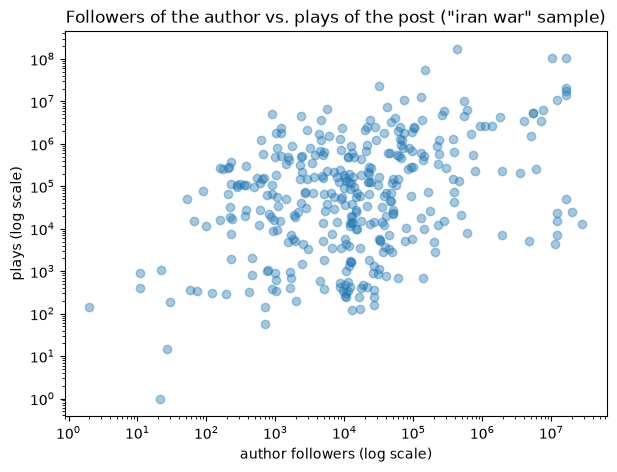

In [51]:
plt.figure(figsize=(7, 5))
sns.regplot(x='author_followers', y='plays', data=df_sel, scatter_kws={'alpha': 0.4}, fit_reg=False)   # fit_reg=False: no trend line
plt.xscale('log')     # logarithmic axes: 1k, 10k, 100k, and 1M are equally far apart
plt.yscale('log')
plt.title('Followers of the author vs. plays of the post ("iran war" sample)')
plt.xlabel('author followers (log scale)')
plt.ylabel('plays (log scale)')
plt.show()

**Methods question.** What does the weak correlation between followers and plays say about how TikTok distributes attention?

WRITE HERE
Since most of the content works with the recommendation engines and not strict deterministic follower --> content relations most of the views of content are not by followers but rather by people that get that video in their fyp or reels or whatever. The same applies for Instagram.

**Task 5.4 (given)** — A correlation matrix of the numerical columns of `df_sel` as a heatmap, as in the lecture. Run the cell and read the matrix: which pairs of metrics move together, and which do not?

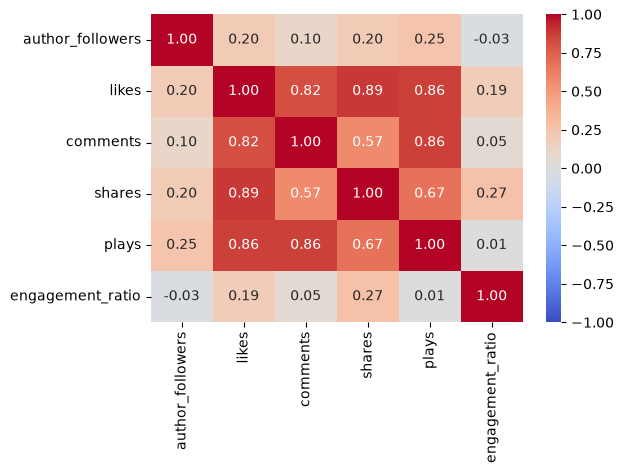

In [54]:
numeric = df_sel.select_dtypes(include='number').drop(columns=['id'])   # only numerical columns; id is a number but not a quantity

plt.figure(figsize=(6, 4))
sns.heatmap(numeric.corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.show()

## 6. Grouping

**Task 6.1 (RQ2)** — How many posts are there per `sound_type`?

In [61]:
# hint: .groupby().size()
df_sel.groupby('sound_type').size()

sound_type
music                     67
own sound                248
reused original sound     38
dtype: int64

**Task 6.2 (RQ2)** — The *median* number of plays per `sound_type`.

In [62]:
# hint: .groupby()['plays'].median()
df_sel.groupby('sound_type')['plays'].median()

sound_type
music                    127600.0
own sound                 39650.0
reused original sound    462650.0
Name: plays, dtype: float64

**Methods question.** Why the median rather than the mean here? And what does the result suggest about the role of reused sounds, compared with what Pilipets and Chao (2026) and Bösch and Divon (2024) describe?

WRITE HERE
I think for comparisons of that kind the median is better because it applies the same cutoff (50%) to every distribution while the mean can be very much affected by uneven data distributions. In this case its heavily skewed towards the right side (ceiling effects) because a few posts can have million of streams. Reused original sounds are highest because people already know them and therefore recognise them. A good example is Papaoutai from Stromae that was used on Tiktok in a lot of unrelated settings (military, safari...)

**Task 6.3 (RQ1, given)** — Per author: the number of posts, the sum of plays, and the followers. Run the cell and read it: `.agg()` with named columns, as in the lecture, computes several values per group at once; the result is sorted to show the ten authors with the most plays in total.

In [63]:
df_authors = df_sel.groupby('author').agg(
    posts=('id', 'size'),                     # new column = ('existing column', 'function')
    plays_total=('plays', 'sum'),
    followers=('author_followers', 'max')     # 'max' because the followers are the same for all posts of an author
)
df_authors.sort_values('plays_total', ascending=False).head(10)

,posts,plays_total,followers
author,,,
hope.love.grace8,1,175700000,424500
aljazeeraenglish,4,159000000,16600000
inilahcom,1,104300000,10200000
biluxury.usa,1,55800000,146000
molly_mitzzy,1,22600000,32000
mohs3njohari,2,14500000,535700
nob91tv,3,13340600,128200
gbnews,2,10600000,5400000
thedailyshow,1,10600000,11900000


**Methods question.** Look up two or three of these accounts on TikTok. Are they news organizations or individuals? The data have no column for this: what would you need to add to answer RQ1 for all 323 authors?

WRITE HERE
I have checked the first 3 by googling them. Those are "business accounts" so no private persons although I dont think these are serious news outlets

**Task 6.4** — A horizontal bar chart of the number of posts per `sound_type` (largest bar on top), with a title.

<Axes: ylabel='sound_type'>

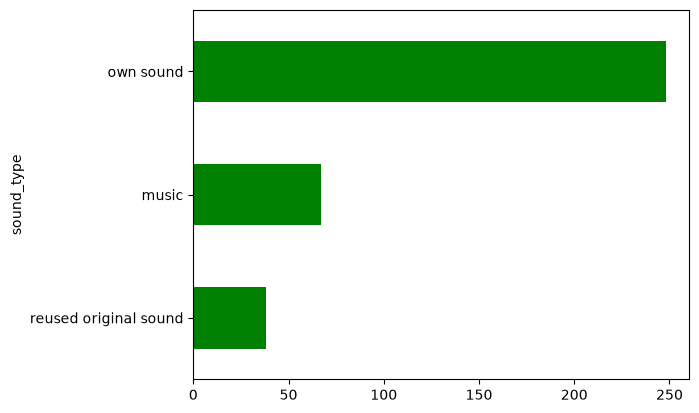

In [ ]:
# hint: .groupby().size().sort_values().plot(kind='barh'), as in the lecture
df_sel.groupby('sound_type').size().sort_values().plot(kind='barh', color='green')

# plt.figure(figsize=(7, 5))
# df_countries['entries'].sort_values(ascending=False).head(15).sort_values().plot(kind='barh', color='steelblue')
# plt.title('Countries with the most Eurovision entries, 1956–2026')
# plt.xlabel('entries')
# plt.ylabel('')
# plt.show()

**Task 6.5 (given)** — Some posts use a green-screen effect, the typical format of news commentary videos. The `effects` column names the effect in the language of the poster ("Green Screen", "Écran vert", "Tela Verde"). Run the cell and read it: the pattern `'green|vert|verde'` is a *regular expression* in which `|` means "or", and `na=False` makes posts without any effect count as `False`. The last line compares the median plays of posts with and without the effect.

In [71]:
df_sel['green_screen'] = df_sel['effects'].str.contains('green|vert|verde', case=False, na=False)   # | means 'or'; na=False: no effect -> False
print(df_sel['green_screen'].value_counts())
df_sel.groupby('green_screen')['plays'].median()

green_screen
False    317
True      36
Name: count, dtype: int64


green_screen
False    97600.0
True      6723.0
Name: plays, dtype: float64

## 7. Hashtags

**Task 7.1 (RQ4, given)** — The `hashtags` column holds several values per cell. Run the cell and read the chain of methods from left to right: drop the posts without hashtags, split each cell at the commas (in this file the separator is a **comma**, not the semicolon of the lecture's credits), give every hashtag its own row with `explode()`, strip spaces, and lower-case everything. Then count the 15 most frequent ones.

In [72]:
# read from left to right: posts without hashtags out -> split at commas -> one row per hashtag -> strip spaces -> lower case
se_tags = df_sel['hashtags'].dropna().str.split(',').explode().str.strip().str.lower()
se_tags.value_counts().head(15)

hashtags
iran            156
fyp              54
war              53
usa              31
breakingnews     27
iranwar          26
israel           26
news             24
viral            23
geopolitics      21
trump            20
edit             14
iran🇮🇷           14
middleeast       13
foryou           11
Name: count, dtype: int64

**Task 7.2** — A horizontal bar chart of the ten most frequent hashtags.

<Axes: ylabel='hashtags'>

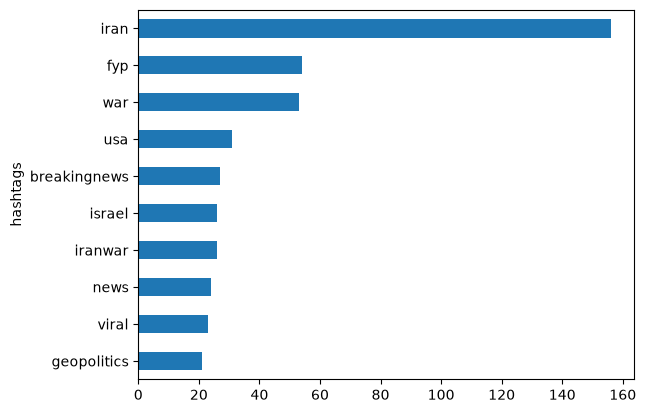

In [75]:
# hint: .value_counts().head(10).sort_values().plot(kind='barh')
se_tags.value_counts().head(10).sort_values().plot(kind='barh')

**Task 7.3 (RQ4)** — Which hashtags travel together with #iran? Produce a table of the most frequent *pairs* of hashtags among the posts that carry the hashtag `iran`. This needs a loop over the hashtags of each post and a count of all pairs, which is more than we covered in the lecture, so here, you may need help from AI.

*Verify:* take the most frequent pair from the table and count it by hand with two `str.contains()` filters on `df_sel['hashtags']`. Do the numbers match? If not, find out why (upper and lower case? the separator? hashtags that contain another hashtag as a part, such as `iranwar` containing `iran`?).

In [76]:
# AI-allowed task: a table of the most frequent hashtag pairs among posts tagged 'iran'
from itertools import combinations   # all pairs from a list: ['a','b','c'] -> (a,b), (a,c), (b,c)
from collections import Counter      # a dictionary that counts things

# one list of clean hashtags per post (same cleaning as Task 7.1); set() removes duplicates, sorted() fixes the order
# so that ('iran', 'war') and ('war', 'iran') count as the same pair
tags_per_post = df_sel['hashtags'].dropna().str.split(',').apply(
    lambda tags: sorted(set(t.strip().lower() for t in tags if t.strip() != ''))
)

# keep only the posts that carry exactly the hashtag 'iran' ('iranwar' does not count)
tags_iran = tags_per_post[tags_per_post.apply(lambda tags: 'iran' in tags)]
print('posts with #iran:', len(tags_iran))

# loop over the posts, and within each post over all pairs of its hashtags, and count them
pair_counts = Counter()
for tags in tags_iran:
    for pair in combinations(tags, 2):
        pair_counts[pair] += 1

# turn the counts into a table, most frequent first
df_pairs = pd.DataFrame([(a, b, n) for (a, b), n in pair_counts.most_common()],
                        columns=['tag_1', 'tag_2', 'posts'])
df_pairs.head(20)

posts with #iran: 156


,tag_1,tag_2,posts
0,iran,war,44
1,fyp,iran,27
2,iran,usa,22
3,iran,israel,20
4,breakingnews,iran,17
5,geopolitics,iran,16
6,iran,news,16
7,iran,trump,15
8,iran,iranwar,11
9,iran,viral,11


In [88]:
# verification: count the most frequent pair by hand with two str.contains() filters
df_sel[df_sel['hashtags'].str.contains('iran', case=False, na=False) & df_sel['hashtags'].str.contains('war', case=False, na=False)]


,id,author,author_full,author_followers,body,timestamp,tiktok_url,music_name,music_author,likes,...,shares,plays,hashtags,effects,is_sensitive,is_paid_partnership,engagement_ratio,music_type,sound_type,green_screen
1,7694261148136328479,prof.jiang2,Prof. Jiang,45900,thus war in middle east surprised me#profjiang...,2026-10-08 11:43:34,https://www.tiktok.com/@prof.jiang2/video/7694...,audio originale,mihaii,2146,...,176,45100,"profjiang,middleeastwar,iranwar,podcast,creato...",NaN,no,no,5.337029,template,reused original sound,False
7,7696098938339822879,margeretclure,margeretclure,10700,Iran Warns it Will Target Data Centers if US R...,2026-10-13 10:35:17,https://www.tiktok.com/@margeretclure/video/76...,original sound,margeretclure,4,...,1,252,"war,iran,us,datecenter,fyp",NaN,no,no,1.984127,original sound,own sound,False
37,7695812183803841805,massi.maredona,Massi Maredona,14800,BREAKING: Iran dares Trump to send US troops a...,2026-10-12 16:02:03,https://www.tiktok.com/@massi.maredona/video/7...,original sound - Massi Maredona,Massi Maredona,898,...,102,24600,"usa,iran,trump,war,breaking",NaN,no,no,4.410569,template,own sound,False
39,7695199105659768065,23maly_,23MALY👽,51400,🚨 Superpetroleiro explode após atingir mina no...,2026-10-11 00:22:48,https://www.tiktok.com/@23maly_/video/76951991...,som original,23MALY👽,3626,...,252,152100,"iran,new,war,ormuz,noticias",NaN,no,no,2.700197,template,own sound,False
44,7694984036862758176,nob91tv,NOB 91 ★,128200,Who Won 12 DAY WAR 🔥 #iranwar #fyppppppppppp...,2026-10-10 10:28:12,https://www.tiktok.com/@nob91tv/video/76949840...,original sound,sarcasm_104,742,...,18,17800,"iranwar,fypppppppppppppp,viralvideos,العراق_ال...",NaN,no,no,4.443820,original sound,reused original sound,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
289,7627853359122304288,derhater,DerHater,100,—❗️🇺🇸/🇮🇷 WATCH: IRIB has released footage of t...,2026-04-12 12:46:53,https://www.tiktok.com/@derhater/video/7627853...,Originalton,DerHater,211,...,33,11700,"news,navy,ship,iran,war",NaN,no,no,2.162393,template,own sound,False
312,7612654418097360148,molly_mitzzy,𝑴𝒂𝒓𝒊𝒂,32000,"""world peace"" they said. #war #iran #america #...",2026-03-02 13:47:12,https://www.tiktok.com/@molly_mitzzy/video/761...,Blow,Kesha,5300000,...,615100,22600000,"war,iran,america,ww3,2026",NaN,no,no,26.218142,template,music,False
317,7616020485620387102,slice828,Slice Therapy,100900,Iran show his Missiles power attitude video #I...,2026-03-11 15:29:24,https://www.tiktok.com/@slice828/video/7616020...,original sound,Prakash 🥷🇳🇵,160800,...,2914,2500000,"iran,trending,foryou,fyp,warnews",NaN,no,no,6.626720,original sound,reused original sound,False
349,7695515256038165793,eaglenews29,𝙀𝙖𝙜𝙡𝙚 𝙉𝙚𝙬𝙨🦅,1640,A senior Iranian official is warning that Tehr...,2026-10-11 20:49:33,https://www.tiktok.com/@eaglenews29/video/7695...,Block Breaker,Yarrow Picker,15,...,0,952,"iran,straitofhormuz,middleeast,worldnews,geopo...",NaN,no,no,1.575630,template,music,False


**Methods question.** With which other topics, places, or actors does #iran travel in this sample? And did your hand count match the table?

WRITE HERE
Hand count didnt match the table, because it travelled with iranwar, nowar. So it included every hashtag that had the core "war" or "iran" in it like with booleans "iran*" and "*war" (Truncation).

## 8. Time series

**Task 8.1 (RQ3)** — Count the posts per week for all posts from 2026 and plot the result as a line, with a title. (In the lecture we grouped by year; here `.dt.to_period('W')` gives the week of each timestamp.)

<Axes: xlabel='timestamp'>

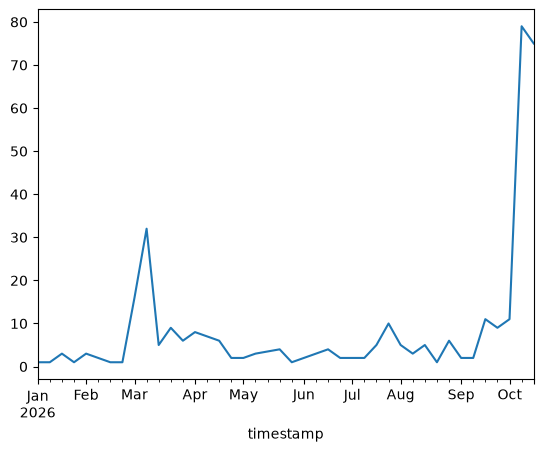

In [91]:
# hint: filter on timestamp >= '2026-01-01', then .groupby(df_2026['timestamp'].dt.to_period('W')).size(), then .plot()
df_2026 = df_sel[df_sel['timestamp'] >= '2026-01-01']
df_2026.groupby(df_2026['timestamp'].dt.to_period('W')).size().plot()

**Task 8.2 (given)** — Posts per *day* in October 2026. Run the cell and read it: the filter keeps the October posts, and `.dt.date` turns each timestamp into a calendar day to group by.

In [92]:
df_oct = df_sel[df_sel['timestamp'] >= '2026-10-01']
df_oct.groupby(df_oct['timestamp'].dt.date).size()    # .dt.date: the calendar day of each timestamp (above, .dt.to_period('W') gave the week)

timestamp
2026-10-01     1
2026-10-03     2
2026-10-04     3
2026-10-05     2
2026-10-06    12
2026-10-07     4
2026-10-08    15
2026-10-09    13
2026-10-10    14
2026-10-11    19
2026-10-12    57
2026-10-13    18
dtype: int64

**Methods question.** There are two peaks, one in late February/March and one in the days before the collection. Which of the two is about the war and which is about the search engine? What would you need to tell them apart?

WRITE HERE
The first is about the war because it started end of january so that is the inflation caused by the importance of the topic. The last is inflated by the search engine. Since the hashtags are not helpful to tell them apart we could look at the authors and exclude private people (?) or use a cutoff before that. 

## 9. Writing back and documenting

**Task 9.1** — Save `df_sel` as a CSV file (without the index) in your Drive.

In [93]:
# hint: .to_csv() with index=False
df_sel.to_csv('df_sel.csv', index=False)

**Methods question.** Data examination and documentation as a reminder for yourself (four to six sentences, in your own words): what do these data contain, what do they leave out (think of the videos themselves, the moment of collection, the empty columns, the languages), and what did you do to them in this notebook (the separator, the dropped columns, the derived columns and their residue)? This is the kind of paragraph the project report asks for.

WRITE HERE
The data contains metadata about a specific dataset collected on TikTok. It contains information about interaction with the content, which kind of music is used, the title, the author, dates and the hashtags. We cleaned the dataset to being able to compute. Caveat here is that statistical power is reduced by dropping columns and the sample is maybe not saturated anymore. Additionally the data usually just shows how its described but does not give any qualitative insights and if the annotation that is made by the users is actually correct. Some data points are inflated and the distribution is very often skewed. Since we dont have insights of the context and cannot control for it it might confound with a lot of other variables.

**Important.** Run the next cell to make an HTML file of your notebook for Canvas. It downloads automatically. First save the notebook (Ctrl+S, or ⌘+S on a Mac): the cell reads the notebook as it is on your screen, and if that does not work, it looks for your saved copy in Google Drive. If you are asked to allow access to your Google Drive, please confirm. Before you hand it in, open the HTML file and check that all your results are there. Its first line says when and how it was made.

In [ ]:
#Keep cell
# Makes an HTML file of this notebook (local version for VS Code / Jupyter, no Google Drive needed)
# FIRST save the notebook (⌘+S): the HTML is made from the saved file, not from what is on screen
import re
import nbformat
from nbconvert import HTMLExporter
from datetime import datetime

notebook_file = 'Week2_Workshop.ipynb'
html_file = 'Week2_Workshop.html'

nb = nbformat.read(notebook_file, as_version=4)
body, _ = HTMLExporter().from_notebook_node(nb)

stamp = f'<p>Made on {datetime.now():%Y-%m-%d %H:%M} from {notebook_file} with nbconvert</p>'
body = re.sub(r'(<body[^>]*>)', r'\1' + stamp, body, count=1)   # put the stamp at the top of the page

with open(html_file, 'w', encoding='utf-8') as f:
    f.write(body)
print('Saved', html_file, '- open it and check that all your results are there before handing it in')

## References

* Bösch, M., & Divon, T. (2024). The sound of disinformation: TikTok, computational propaganda, and the invasion of Ukraine. *New Media & Society, 26*(9), 5081–5106. https://doi.org/10.1177/14614448241251804
* Peeters, S. (2022). *Zeeschuimer* [Computer software]. Digital Methods Initiative. https://github.com/digitalmethodsinitiative/zeeschuimer
* Pilipets, E., & Chao, J. (2026). Noise in sonic social media: Memetic soundscapes of Deep TikTok. *New Media & Society, 28*(8), 4095–4114. https://doi.org/10.1177/14614448251358752

That's it. Pandas can get complicated, but the sequence you followed twice this week — open, inspect, clean, select, analyze, write back — is the same for almost every dataset you will meet, and so are the questions that go with it.